<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">DISSIPATIVE PARTICLE DYNAMICS · NOTEBOOK 4 OF 4</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">A self-assembling<br>block copolymer coating</h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">Amphiphilic diblock copolymers in water self-assemble into a film on a hydrophilic, cellulose-like substrate: a small version of the DPD coating models of paper and board packaging, run in LAMMPS, with the block length ratio and a hydrophobic homopolymer as exercises.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">System: 8640 beads in 12 × 12 × 20 r<sub>C</sub>³, A<sub>4</sub>B<sub>3</sub> at 25 %, frozen substrate, Δt = 0.05 τ · programs: LAMMPS (pip), NumPy</p>
</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The notebook answers three questions:

1. Which film does the diblock A<sub>4</sub>B<sub>3</sub> form on the substrate?
2. How much water gets into the hydrophobic layer of the film?
3. How do a short hydrophobic block (A<sub>6</sub>B<sub>1</sub>) and an added hydrophobic homopolymer
   (B<sub>19</sub>) change the film? (exercises)

Paper is porous and hydrophilic, so water wets it. A coating of amphiphilic block copolymers can protect it: the
hydrophilic block sticks to the paper and the hydrophobic block forms a water barrier. The coating models of [1–3]
study how the block length ratio and the composition of the coating mixture control such films. Their simulations
used a box of 40 × 40 × 40 r<sub>C</sub>³ (about 190 000 beads) and 1.5 × 10⁶ steps of LAMMPS; the box here is about
20 times smaller and the runs about 75 times shorter, so the results are qualitative trends, not converged numbers.
The repulsions come from notebook 02, the method from notebooks 01 and 03. A full run takes about fifteen minutes on
a laptop and longer on the Colab CPU.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kourosh-h/dpd-teaching/blob/main/notebooks/04_copolymer_coating.ipynb)

Folders: `figures/` (every plot of the notebook as a PDF file), `work/` (LAMMPS data files), both written when the
notebook runs.

<p>Sections: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">model</span> <span style="background-color:#3D5A80; color:#ffffff; padding:2px 9px; border-radius:10px;">system</span> <span style="background-color:#9C4F6E; color:#ffffff; padding:2px 9px; border-radius:10px;">film</span> <span style="background-color:#4F772D; color:#ffffff; padding:2px 9px; border-radius:10px;">water</span> <span style="background-color:#6D597A; color:#ffffff; padding:2px 9px; border-radius:10px;">exercises</span> <span style="background-color:#005F73; color:#ffffff; padding:2px 9px; border-radius:10px;">limits</span> <span style="background-color:#37474F; color:#ffffff; padding:2px 9px; border-radius:10px;">summary</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">references</span></p>

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code installs the packages that are missing: NumPy, SciPy, pandas, Matplotlib, and ASE with py3Dmol for the 3D views, and LAMMPS with the MPI library it needs. After an install, a restart of the kernel may be needed.</div>

In [ ]:
# Installs the packages of this notebook that are missing (on the laptop and on Colab).
# If it installs something and a later import still fails, restart the kernel and run the notebook again.
import importlib
import importlib.util
import subprocess
import sys

PACKAGES = {  # module name: pip package
    'numpy': 'numpy',
    'scipy': 'scipy',
    'pandas': 'pandas',
    'matplotlib': 'matplotlib',
    'ase': 'ase',
    'py3Dmol': 'py3Dmol',
    'mpich': 'mpich',
    'lammps': 'lammps',
}
missing = [package for module, package in PACKAGES.items() if importlib.util.find_spec(module) is None]
if missing:
    print("installing:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *missing], check=True)
    importlib.invalidate_caches()
else:
    print("all packages are installed")

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code loads the MPI library that the pip version of LAMMPS needs. Without it, Colab and Linux stop with "libmpi.so.12: cannot open shared object file"; on the Mac it does no harm.</div>

In [2]:
# The LAMMPS pip wheel needs the MPI library of the mpich pip package. pip puts it in a folder that Linux does not
# search (on Colab: "libmpi.so.12: cannot open shared object file"), so it is loaded here by its full path.
import ctypes
import importlib.metadata
import subprocess
import sys

try:
    mpich_files = importlib.metadata.files("mpich")
except importlib.metadata.PackageNotFoundError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", "mpich"], check=True)
    mpich_files = importlib.metadata.files("mpich")
for file in mpich_files:
    if file.name in ("libmpi.so.12", "libmpi.12.dylib"):
        ctypes.CDLL(str(file.locate()), mode=ctypes.RTLD_GLOBAL)
        print("loaded the MPI library for LAMMPS:", file.name)

loaded the MPI library for LAMMPS: libmpi.so.12


<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code imports the packages, including LAMMPS, and sets the box, the substrate, the DPD and bond parameters, the folders, colors and plot settings.</div>

In [3]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from lammps import lammps

RHO = 3.0                              # bead number density (r_C^-3)
BOX = np.array([12.0, 12.0, 20.0])     # box (r_C); the substrate slab lies across the middle of z
SLAB = 3.0                             # thickness of the substrate slab (r_C)
GAMMA = 4.5                            # friction coefficient; noise amplitude sqrt(2 gamma k_BT) = 3
DT = 0.05                              # time step (tau), as in [1]
BOND_K = 40.0                          # LAMMPS harmonic bond E = K (r - r0)^2: force 2K (r - r0) = 80 (r - 1)
BOND_R0 = 1.0                          # equilibrium bond length (r_C)
WALL_K = 60.0                          # force constant of the wall inside the slab (k_BT/r_C^2)
THREADS = 2                            # OpenMP threads of LAMMPS (Colab has two CPU cores)
WORK = Path('work')
WORK.mkdir(exist_ok=True)

FIGURES = Path('figures')
FIGURES.mkdir(exist_ok=True)

# colors of the bead types: A hydrophilic or minority block, B hydrophobic or majority block, B19 hydrophobic
# homopolymer, C substrate, D water; ink: the single-component fluid and the model lines
C = {'A': '#0C54B4', 'B': '#B7371B', 'B19': '#E4840C', 'C': '#795548', 'D': '#2CA02C', 'ink': '#282B28'}

plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'], 'pdf.fonttype': 42,
                     'mathtext.default': 'it', 'axes.unicode_minus': False, 'font.size': 10.0,
                     'axes.labelsize': 10.0, 'xtick.labelsize': 9.5, 'ytick.labelsize': 9.5, 'legend.fontsize': 9.0,
                     'axes.linewidth': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelpad': 2.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.major.size': 4.2, 'ytick.major.size': 4.2, 'xtick.major.width': 1.0,
                     'ytick.major.width': 1.0, 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,
                     'xtick.minor.width': 0.7, 'ytick.minor.width': 0.7, 'xtick.minor.visible': True,
                     'ytick.minor.visible': True, 'xtick.major.pad': 3.0, 'ytick.major.pad': 3.0,
                     'lines.linewidth': 1.45, 'lines.markersize': 4.25, 'lines.dashed_pattern': [4.0, 2.2],
                     'lines.scale_dashes': False, 'legend.frameon': False, 'legend.handlelength': 1.8,
                     'legend.handletextpad': 0.4, 'legend.columnspacing': 1.6, 'savefig.dpi': 300})


def two_panels(height=2.6):
    """
    Figure 7.0 inches wide with two panels side by side, (a) and (b), 1.61 inches high; a figure higher than 2.6
    inches has more room above the panels, for a legend of two rows.
    """
    fig = plt.figure(figsize=(7.0, height))
    left = fig.add_axes([0.085, 0.429 / height, 0.385, 1.612 / height])
    right = fig.add_axes([0.595, 0.429 / height, 0.385, 1.612 / height])
    left.text(-0.2, 1.03, '(a)', transform=left.transAxes, fontsize=11.0, va='bottom')
    right.text(-0.2, 1.03, '(b)', transform=right.transAxes, fontsize=11.0, va='bottom')
    return fig, left, right


def top_legend(fig, entries):
    """The legend entries in one row at the top of a figure."""
    fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(entries))


def one_panel(height=2.6, left=0.085):
    """Figure 7.0 inches wide with one panel, 1.61 inches high, at the same height as the panels of two_panels."""
    fig = plt.figure(figsize=(7.0, height))
    axes = fig.add_axes([left, 0.429 / height, 0.98 - left, 1.612 / height])
    return fig, axes


def panel_title(axes, text):
    """A short label at the top center of a panel: the name of what it shows."""
    axes.text(0.5, 1.02, text, transform=axes.transAxes, ha='center', va='bottom')

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>show_3d</code>, which shows a configuration or a trajectory in 3D (drag to rotate, scroll to zoom); the viewers show only while the notebook runs.</div>

In [4]:
# py3Dmol runs on Colab and in Jupyter on the Mac with no widget setup (nglview needs extra setup on Colab)
import py3Dmol
from ase import Atoms


def show_3d(frames, colors, every=1, radius=0.35, width=640, height=420, interval_ms=120):
    """
    Shows one ASE Atoms object, or a list of them (every n-th frame) as a looping movie, with the box edges. The
    bead types are stored as chemical symbols; colors maps each symbol to a color, and symbols not in it are hidden.
    """
    if not isinstance(frames, list):
        frames = [frames]
    frames = frames[::every]
    text = ""
    for frame in frames:  # xyz text with two decimals, which keeps the saved notebook small
        shown = [index for index, symbol in enumerate(frame.get_chemical_symbols()) if symbol in colors]
        text += f"{len(shown)}\n\n"
        for index in shown:
            x, y, z = frame.positions[index]
            text += f"{frame.get_chemical_symbols()[index]} {x:.2f} {y:.2f} {z:.2f}\n"
    view = py3Dmol.view(width=width, height=height)
    view.addModelsAsFrames(text, "xyz")
    for symbol, color in colors.items():
        view.setStyle({"elem": symbol}, {"sphere": {"radius": radius, "color": color}})
    corners = [i * frames[0].cell[0] + j * frames[0].cell[1] + k * frames[0].cell[2]
               for i in (0, 1) for j in (0, 1) for k in (0, 1)]
    for first in range(8):
        for second in range(first + 1, 8):
            if bin(first ^ second).count("1") == 1:  # corners that differ in one direction share an edge
                start = dict(zip("xyz", map(float, corners[first])))
                end = dict(zip("xyz", map(float, corners[second])))
                view.addLine({"start": start, "end": end, "color": "gray"})
    if len(frames) > 1:
        view.animate({"loop": "forward", "interval": interval_ms})
    view.zoomTo()
    view.show()

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">The model<br><span style="font-size:0.72em; font-weight:normal;">four bead types, harmonic bonds and the repulsions of the coating model</span></h2>

Four bead types, numbered 1 to 4 in LAMMPS (type 5 is used in exercise 2):

| Bead | Type | Stands for |
|--|--|--|
| A | 1 | starch, the hydrophilic block |
| B | 2 | random copolymer of styrene (42 wt%) and n-butyl acrylate (58 wt%), the hydrophobic block |
| C | 3 | cellulose substrate |
| D | 4 | water |

Each polymer bead stands for about 5 monomers and each water bead for 33 water molecules, so that all beads have about
the same volume (chapter 3 of [1]). A diblock copolymer A<sub>i</sub>B<sub>j</sub> has i + j = 7 beads, about 35
monomers. Consecutive beads of a chain are joined by harmonic springs with the force constant 80 and the equilibrium
length 1 r<sub>C</sub> of [1], F<sup>bond</sup><sub>ij</sub> = −80 (r<sub>ij</sub> − 1) r̂<sub>ij</sub>. LAMMPS
writes the harmonic bond as E = K(r − r<sub>0</sub>)², whose force is 2K(r − r<sub>0</sub>), so K = 40 here. All
pairs, bonded or not, feel the DPD forces of Groot and Warren [4] (notebook 01) with γ = 4.5. The repulsions are those of Table 3.1 of [1]
(notebook 02 gives their χ):

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code sets the bead types and the repulsion matrix of the coating model.</div>

In [5]:
A, B, SUB, D, B19 = 1, 2, 3, 4, 5      # LAMMPS bead types: A, B, substrate C, water D, homopolymer B19
NAMES = {A: 'A', B: 'B', SUB: 'C', D: 'D', B19: 'B19'}
a = np.array([[25.00, 56.15, 25.00, 35.00],
              [56.15, 25.00, 56.15, 107.0],
              [25.00, 56.15, 25.00, 35.00],
              [35.00, 107.0, 35.00, 25.00]])   # Table 3.1 of [1], order A, B, C, D


def repulsion(first, second):
    """a_ij of two LAMMPS bead types; B19 beads interact as B beads."""
    index = {A: 0, B: 1, SUB: 2, D: 3, B19: 1}
    return a[index[first], index[second]]


pd.DataFrame(a, index=['A', 'B', 'C', 'D'], columns=['A', 'B', 'C', 'D'])

,A,B,C,D
A,25.00,56.15,25.00,35.0
B,56.15,25.00,56.15,107.0
C,25.00,56.15,25.00,35.0
D,35.00,107.00,35.00,25.0


<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#3D5A80; color:#ffffff; padding:8px 14px; border-radius:6px;">Building the system<br><span style="font-size:0.72em; font-weight:normal;">a frozen substrate across the middle of the box, chains and water around it</span></h2>

The substrate is a slab of C beads at density 3 whose positions are fixed during the run, as in [1]. It lies across
the middle of the box; with the periodic boundaries it has two faces, and the film can form on both. The rest of the
box holds water and polymer chains at a total density of 3; the chains are grown as random walks from random starts.

The slab is thin (3 r<sub>C</sub>, against 5 in [1]), and a frozen layer of soft beads is not a barrier: with
a<sub>AC</sub> = 25, A beads would diffuse into it and out on the other face. A wall keeps the faces apart: a mobile
bead inside the slab is pushed back to the nearest face with a force k d, where d is its depth and k = 60
k<sub>B</sub>T/r<sub>C</sub>². In LAMMPS this is a force from an atom-style variable (`fix addforce`). The frozen
C beads still give the substrate its chemistry through a<sub>iC</sub>.

The study of [2] found complete films at 11.25 % copolymer (by bead number) in a solution 35 r<sub>C</sub> high
above one face. The solution here is 17 r<sub>C</sub> high and has two faces, so 25 % copolymer is used to give a
comparable amount of polymer per substrate area. The models of [1–3] let the polymers form micelles in water for 10⁶
steps before the substrate was added; here the chains start dispersed next to the substrate.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines <code>build</code> and the LAMMPS data file, and builds the A<sub>4</sub>B<sub>3</sub> system.</div>

In [6]:
Z_MID, HALF = BOX[2] / 2, SLAB / 2     # center and half thickness of the substrate slab


def build(chains, seed=0):
    """
    Substrate slab, chains and water. chains is a list of (sequence of bead types, bead fraction of the solution);
    the chains are random walks with steps of 0.9 r_C from random starts. Returns positions, types, molecule numbers
    and bonds (LAMMPS atom numbers, from 1).
    """
    rng = np.random.default_rng(seed)
    count_sub = int(RHO * BOX[0] * BOX[1] * SLAB)
    substrate = rng.random((count_sub, 3)) * [BOX[0], BOX[1], SLAB] + [0, 0, Z_MID - HALF]
    count_solution = int(RHO * np.prod(BOX)) - count_sub

    def in_solution(count):
        """Random points in the solution, above the slab and round the periodic boundary to below it."""
        points = rng.random((count, 3)) * [BOX[0], BOX[1], BOX[2] - SLAB]
        points[:, 2] += Z_MID + HALF
        return points % BOX

    pos, types, molecules, bonds = [], [], [], []
    molecule = 0
    for sequence, fraction in chains:
        for start in in_solution(int(round(fraction * count_solution / len(sequence)))):
            molecule += 1
            bead = start
            for k, kind in enumerate(sequence):
                if k > 0:
                    step = rng.standard_normal(3)
                    bead = pos[-1] + 0.9 * step / np.linalg.norm(step)
                    bonds.append([count_sub + len(pos), count_sub + len(pos) + 1])
                pos.append(bead)
                types.append(kind)
                molecules.append(molecule)
    count_water = count_solution - len(pos)
    pos = np.vstack([substrate, np.array(pos) % BOX, in_solution(count_water)])
    types = np.array([SUB] * count_sub + types + [D] * count_water)
    molecules = np.array([0] * count_sub + molecules + [0] * count_water)
    return pos, types, molecules, np.array(bonds)


def write_data(path, pos, types, molecules, bonds):
    """LAMMPS data file (atom style bond) of the system, with five bead types."""
    lines = [f'coating\n\n{len(pos)} atoms\n{len(bonds)} bonds\n5 atom types\n1 bond types\n',
             f'0 {BOX[0]} xlo xhi\n0 {BOX[1]} ylo yhi\n0 {BOX[2]} zlo zhi\n',
             'Masses\n\n1 1.0\n2 1.0\n3 1.0\n4 1.0\n5 1.0\n', 'Atoms # bond\n']
    for index in range(len(pos)):
        x, y, z = pos[index]
        lines.append(f'{index + 1} {molecules[index]} {types[index]} {x:.4f} {y:.4f} {z:.4f}')
    lines.append('\nBonds\n')
    for index, (first, second) in enumerate(bonds):
        lines.append(f'{index + 1} 1 {first} {second}')
    path.write_text('\n'.join(lines) + '\n')


A4B3 = [A, A, A, A, B, B, B]
pos0, types0, molecules0, bonds0 = build([(A4B3, 0.25)])
print(len(pos0), 'beads:', np.sum(types0 == SUB), 'substrate,', molecules0.max(), 'A4B3 chains,',
      np.sum(types0 == D), 'water')

8640 beads: 1296 substrate, 262 A4B3 chains, 5510 water


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 1.** The A<sub>4</sub>B<sub>3</sub> system at the start: substrate brown, A blue, B red; water is hidden.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the start configuration in 3D (Viewer 1).</div>

In [ ]:
symbols = {A: 'N', B: 'O', SUB: 'Si', D: 'H', B19: 'S'}
colors = {'N': C['A'], 'O': C['B'], 'Si': C['C'], 'S': C['B19']}      # water (H) is hidden
show_3d(Atoms([symbols[t] for t in types0], positions=pos0, cell=BOX), colors, radius=0.3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#9C4F6E; color:#ffffff; padding:8px 14px; border-radius:6px;">The film<br><span style="font-size:0.72em; font-weight:normal;">self-assembly of A₄B₃ and the density profiles across the film</span></h2>

The run uses Δt = 0.05 τ, as in [1], for 20 000 steps (1000 τ). During the last third, the density profiles
perpendicular to the substrate are collected every 50 τ. Since the film can grow on both faces, the two sides are
folded together: z is the distance from the nearest face of the substrate, negative inside it. The bead probability
distribution P(z) is normalized to 1 for each bead type, as in [1],

$$\int P(z)\,dz = 1 ,$$

so the curves show where each species sits, independent of its amount.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the LAMMPS setup, the height, the profiles and <code>simulate</code>, and runs the A<sub>4</sub>B<sub>3</sub> system for 1000 τ.</div>

In [8]:
def start_lammps(data_file, seed=4321):
    """LAMMPS with the coating system: DPD pairs, harmonic bonds, a frozen substrate and the wall inside it."""
    lmp = lammps(cmdargs=['-log', 'none', '-screen', 'none', '-sf', 'omp', '-pk', 'omp', str(THREADS)])
    pair_lines = '\n'.join(f'pair_coeff {i} {j} {repulsion(i, j)} {GAMMA} 1.0'
                           for i in range(1, 6) for j in range(i, 6))
    lmp.commands_string(f"""
units lj
atom_style bond
comm_modify vel yes cutoff 3.0
read_data {data_file}
bond_style harmonic
bond_coeff 1 {BOND_K} {BOND_R0}
special_bonds lj 1 1 1
pair_style dpd 1.0 1.0 {seed}
{pair_lines}
neighbor 0.3 bin
neigh_modify every 1 delay 0 check yes
group substrate type {SUB}
group mobile subtract all substrate
velocity mobile create 1.0 {seed + 1} mom yes
velocity substrate set 0.0 0.0 0.0
# a mobile bead at depth d inside the slab is pushed back to the nearest face with the force WALL_K d
variable depth atom {HALF}-abs(z-{Z_MID})
variable wall atom {WALL_K}*v_depth*(v_depth>0)*(2*(z>{Z_MID})-1)
fix wall mobile addforce 0.0 0.0 v_wall
fix integrate mobile nve
compute mobile_temp mobile temp
thermo_modify temp mobile_temp
timestep {DT}
""")
    return lmp


def height(pos):
    """Distance from the nearest face of the substrate slab (r_C), negative inside the slab."""
    return np.abs(pos[:, 2] % BOX[2] - Z_MID) - HALF


EDGES = np.linspace(-HALF, BOX[2] / 2 - HALF, 61)
CENTERS = 0.5 * (EDGES[1:] + EDGES[:-1])


def profiles(pos, types):
    """P(z) of every bead type against the distance from the substrate, each normalized to 1."""
    z = height(pos)
    result = {}
    for kind in np.unique(types):
        result[kind] = np.histogram(z[types == kind], EDGES, density=True)[0]
    return result


def simulate(pos, types, molecules, bonds, name, total_tau=1000, every_tau=50, seed=1):
    """
    Runs the system; returns the positions every every_tau and the mean profiles over the last third of the run.
    """
    write_data(WORK / f'{name}.data', pos, types, molecules, bonds)
    lmp = start_lammps(WORK / f'{name}.data', seed=4321 + seed)
    ids = np.array(lmp.numpy.extract_atom('id'))[:len(pos)]
    frames, collected, temperatures = [pos % BOX], [], []
    start = time.time()
    for block in range(int(total_tau / every_tau)):
        lmp.command(f'run {int(every_tau / DT)}')
        ids = np.array(lmp.numpy.extract_atom('id'))[:len(pos)]
        x = np.array(lmp.numpy.extract_atom('x'))[:len(pos)][np.argsort(ids)] % BOX
        frames.append(x)
        temperatures.append(lmp.get_thermo('temp'))
        if (block + 1) * every_tau > 2 * total_tau / 3:
            collected.append(profiles(x, types))
    lmp.close()
    mean = {kind: np.mean([p[kind] for p in collected], axis=0) for kind in collected[0]}
    print(f'{name}: {len(pos)} beads, {total_tau:g} tau in {time.time() - start:.0f} s, '
          f'k_BT of the mobile beads = {np.mean(temperatures[len(temperatures) // 3:]):.3f}')
    return frames, mean


frames43, profile43 = simulate(pos0, types0, molecules0, bonds0, 'A4B3')

A4B3: 8640 beads, 1000 tau in 315 s, k_BT of the mobile beads = 1.045


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 2.** Film formation of A<sub>4</sub>B<sub>3</sub> over 1000 τ, one frame every 50 τ; water is hidden.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code plays the run as a 3D movie (Viewer 2).</div>

In [ ]:
movie = [Atoms([symbols[t] for t in types0], positions=x, cell=BOX) for x in frames43]
show_3d(movie, colors, radius=0.3, interval_ms=250)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 1.** The A<sub>4</sub>B<sub>3</sub> film after 1000 τ: (a) side view of the box without water, z along the
horizontal axis; (b) density profiles of A, B and water against the distance from the substrate (shaded), both faces
folded together. `figures/film_A4B3.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines the side view and the profile plot, draws Figure 1 (<code>figures/film_A4B3.pdf</code>) and gives the heights of the A and B maxima.</div>

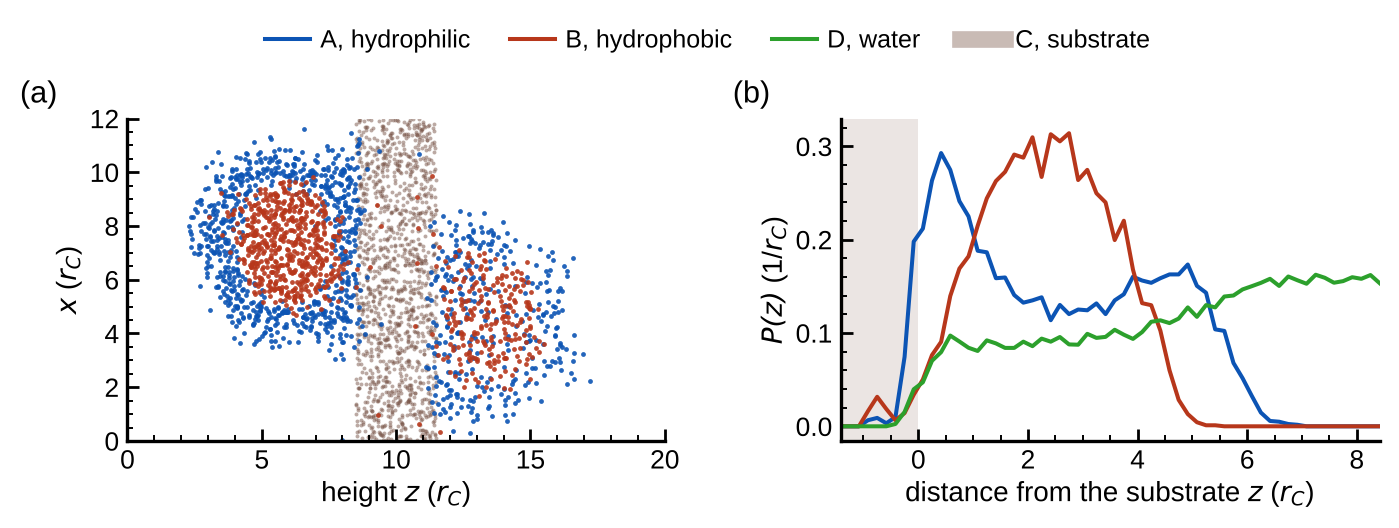

,height of the maximum (r_C)
bead type,
A,0.42
B,2.75


In [10]:
def side_view(axes, pos, types, kinds=(SUB, A, B)):
    """Side view of the box without water: z along the horizontal axis, x along the vertical axis."""
    for kind in kinds:
        mask = types == kind
        axes.scatter(pos[mask, 2], pos[mask, 0], s=2 if kind == SUB else 3, color=C[NAMES[kind]], lw=0,
                     alpha=0.5 if kind == SUB else 0.9)
    axes.set_xlim(0, BOX[2])
    axes.set_ylim(0, BOX[0])
    axes.set_aspect('equal')
    axes.set_xlabel(r'height $z$ ($r_C$)')
    axes.set_ylabel(r'$x$ ($r_C$)')


def plot_profile(axes, profile, kinds=(A, B, D)):
    """P(z) of the given bead types against the distance from the substrate (shaded)."""
    for kind in kinds:
        axes.plot(CENTERS, profile[kind], color=C[NAMES[kind]])
    axes.axvspan(-HALF, 0, color=C['C'], alpha=0.15, lw=0)
    axes.set_xlim(CENTERS[0], CENTERS[-1])
    axes.set_xlabel(r'distance from the substrate $z$ ($r_C$)')
    axes.set_ylabel(r'$P(z)$ (1/$r_C$)')


BEAD_ENTRIES = [Line2D([], [], color=C['A'], label='A, hydrophilic'),
                Line2D([], [], color=C['B'], label='B, hydrophobic'),
                Line2D([], [], color=C['D'], label='D, water'),
                Line2D([], [], color=C['C'], lw=6, alpha=0.4, label='C, substrate')]

fig, left, right = two_panels()
side_view(left, frames43[-1], types0)
plot_profile(right, profile43)
top_legend(fig, BEAD_ENTRIES)
fig.savefig(FIGURES / 'film_A4B3.pdf')
fig.savefig(FIGURES / 'film_A4B3.png', dpi=200)
plt.show()

pd.DataFrame({'height of the maximum (r_C)': [CENTERS[np.argmax(profile43[kind])] for kind in (A, B)]},
             index=pd.Index(['A', 'B'], name='bead type')).round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Film (Figure 1).** In 1000 τ the dispersed chains gather into two large aggregates, one on each face of the
  substrate (Figure 1a, Viewer 2). Each is layered from the substrate outward: A beads on the substrate (maximum at
  z = 0.42 r<sub>C</sub>; a<sub>AC</sub> = 25, so starch and cellulose mix freely and the A blocks anchor the chains),
  a core of B beads (maximum at z = 2.75 r<sub>C</sub>) and a second A layer toward the water (the shoulder at z ≈ 5
  r<sub>C</sub>), which shields the B core from water (χ<sub>BD</sub> ≈ 25). This is the A–B–A order of the films of
  nearly symmetric copolymers in [1, 2], but the aggregates have not yet spread into a continuous film: in [2] the
  micelles formed for 10⁶ steps before they met the substrate, and the films were followed for 1.5 × 10⁶ steps,
  against 2 × 10⁴ here.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#4F772D; color:#ffffff; padding:8px 14px; border-radius:6px;">Water in the film<br><span style="font-size:0.72em; font-weight:normal;">coverage of the two faces and the water at the hydrophobic layer</span></h2>

A barrier coating keeps water away from the substrate. Two simple measures: how the hydrophobic B beads are shared
between the two faces, and the water density at the maximum of the B profile, against bulk water (z > 6.5
r<sub>C</sub>). The atomistic study of [6] looks at water in such layers in detail.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code computes the share of B beads near each face and the water density at the B maximum as a percentage of bulk water.</div>

In [11]:
def face_coverage(pos, types, kind, reach=3.0):
    """Fraction of the beads of one type within reach of the upper and of the lower face of the slab."""
    z = pos[:, 2] % BOX[2] - Z_MID
    mask = types == kind
    upper = np.mean((z[mask] > HALF) & (z[mask] < HALF + reach))
    lower = np.mean((z[mask] < -HALF) & (z[mask] > -HALF - reach))
    return upper, lower


def water_in_film(profile):
    """Height of the B maximum and the water density there relative to bulk water (z > 6.5 r_C)."""
    z_peak = CENTERS[np.argmax(profile[B])]
    bulk = profile[D][CENTERS > 6.5].mean()
    near = np.abs(CENTERS - z_peak) < 0.5
    return z_peak, profile[D][near].mean() / bulk


upper, lower = face_coverage(frames43[-1], types0, B)
z_peak, ratio = water_in_film(profile43)
pd.DataFrame({'value': [upper, lower, z_peak, 100 * ratio]},
             index=['B beads within 3 r_C of the upper face', 'B beads within 3 r_C of the lower face',
                    'height of the B maximum (r_C)', 'water at the B maximum (% of bulk)']).round(3)

,value
B beads within 3 r_C of the upper face,0.251
B beads within 3 r_C of the lower face,0.440
height of the B maximum (r_C),2.750
water at the B maximum (% of bulk),58.858


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Water in the film.** The B beads are shared unevenly between the faces, 44 % within 3 r<sub>C</sub> of the lower face and
  25 % of the upper one; the rest sits further out in the aggregates. The water density at the B maximum is 59 % of
  bulk water. The profile averages over the whole substrate area, so it mixes the B cores with the uncovered parts
  next to the aggregates, where water touches the cellulose: a coating is only as good as its weakest spot, the
  incomplete coverage of [2, 3].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6D597A; color:#ffffff; padding:8px 14px; border-radius:6px;">Exercises<br><span style="font-size:0.72em; font-weight:normal;">block length ratio, a hydrophobic homopolymer and a composition map</span></h2>

**Exercise 1. Block length ratio.** The study of [2] compared A<sub>6</sub>B<sub>1</sub>, A<sub>5</sub>B<sub>2</sub>
and A<sub>4</sub>B<sub>3</sub>. Run the same simulation with A<sub>6</sub>B<sub>1</sub> (a very short hydrophobic
block) and compare the profiles and the water in the film with A<sub>4</sub>B<sub>3</sub>. What does the short B block
do?

**Figure 2.** Density profiles of A, B and water against the distance from the substrate (shaded):
(a) A<sub>4</sub>B<sub>3</sub>, (b) A<sub>6</sub>B<sub>1</sub>. `figures/block_ratio.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 1) runs the A<sub>6</sub>B<sub>1</sub> system, draws Figure 2 (<code>figures/block_ratio.pdf</code>) and gives the B maximum, the water there and the share of A beads near each face for both films.</div>

A6B1: 8640 beads, 1000 tau in 185 s, k_BT of the mobile beads = 1.043


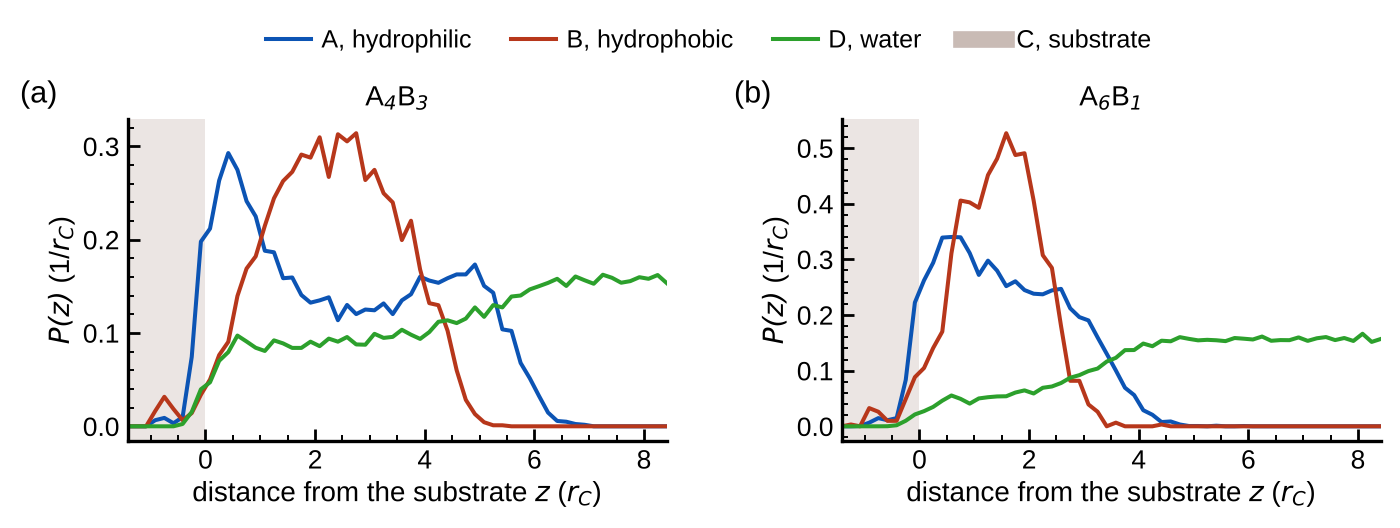

,B maximum at z (r_C),water at the B maximum (% of bulk),A within 3 r_C of the upper face,A within 3 r_C of the lower face
film,,,,
A4B3,2.75,58.86,0.20,0.33
A6B1,1.58,36.54,0.32,0.49


In [12]:
# Solution 1
A6B1 = [A, A, A, A, A, A, B]
pos61, types61, molecules61, bonds61 = build([(A6B1, 0.25)])
frames61, profile61 = simulate(pos61, types61, molecules61, bonds61, 'A6B1')

fig, left, right = two_panels()
plot_profile(left, profile43)
plot_profile(right, profile61)
panel_title(left, 'A$_4$B$_3$')
panel_title(right, 'A$_6$B$_1$')
top_legend(fig, BEAD_ENTRIES)
fig.savefig(FIGURES / 'block_ratio.pdf')
plt.show()

rows = []
for name, profile, frames, types in [('A4B3', profile43, frames43, types0), ('A6B1', profile61, frames61, types61)]:
    z_peak, ratio = water_in_film(profile)
    upper, lower = face_coverage(frames[-1], types, A)
    rows.append({'film': name, 'B maximum at z (r_C)': z_peak, 'water at the B maximum (% of bulk)': 100 * ratio,
                 'A within 3 r_C of the upper face': upper, 'A within 3 r_C of the lower face': lower})
pd.DataFrame(rows).set_index('film').round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 1 (Figure 2).** With one B bead per chain the copolymer is mostly hydrophilic. A<sub>6</sub>B<sub>1</sub> forms
  a thin mixed layer on the substrate, with the B maximum at z = 1.58 r<sub>C</sub> inside the A layer and no separate
  B layer or outer A layer. It covers more of the substrate than A<sub>4</sub>B<sub>3</sub> (49 and 32 % of the A beads
  within 3 r<sub>C</sub> of the two faces, against 33 and 20 %), so the water at the B maximum is lower, 37 % of bulk
  against 59 %. But the layer is hydrophilic, six A beads for each B bead, and gives no hydrophobic barrier. In [2]
  the more hydrophilic copolymers formed such disordered, mixed films, and the nearly symmetric ones the layered
  films. One number does not rank barriers; structure and coverage both matter.

**Exercise 2. Adding a hydrophobic polymer.** Practical coatings often mix the copolymer with a hydrophobic binder
polymer, modeled in [3] as a B<sub>19</sub> homopolymer. Add B<sub>19</sub> chains to an A<sub>3</sub>B<sub>4</sub>
solution (20 % copolymer, 12 % homopolymer) and find where the B<sub>19</sub> beads end up. To tell the two kinds of B
beads apart, the homopolymer beads get a fifth type with the same interactions as B.

**Figure 3.** A<sub>3</sub>B<sub>4</sub> with B<sub>19</sub> after 1000 τ: (a) side view without water, z along the
horizontal axis; (b) density profiles of the copolymer A and B beads and of B<sub>19</sub> against the distance from
the substrate (shaded). `figures/homopolymer_B19.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code (solution 2) runs the A<sub>3</sub>B<sub>4</sub> and B<sub>19</sub> system, draws Figure 3 (<code>figures/homopolymer_B19.pdf</code>) and gives the heights of the three maxima.</div>

A3B4_B19: 8640 beads, 1000 tau in 168 s, k_BT of the mobile beads = 1.035


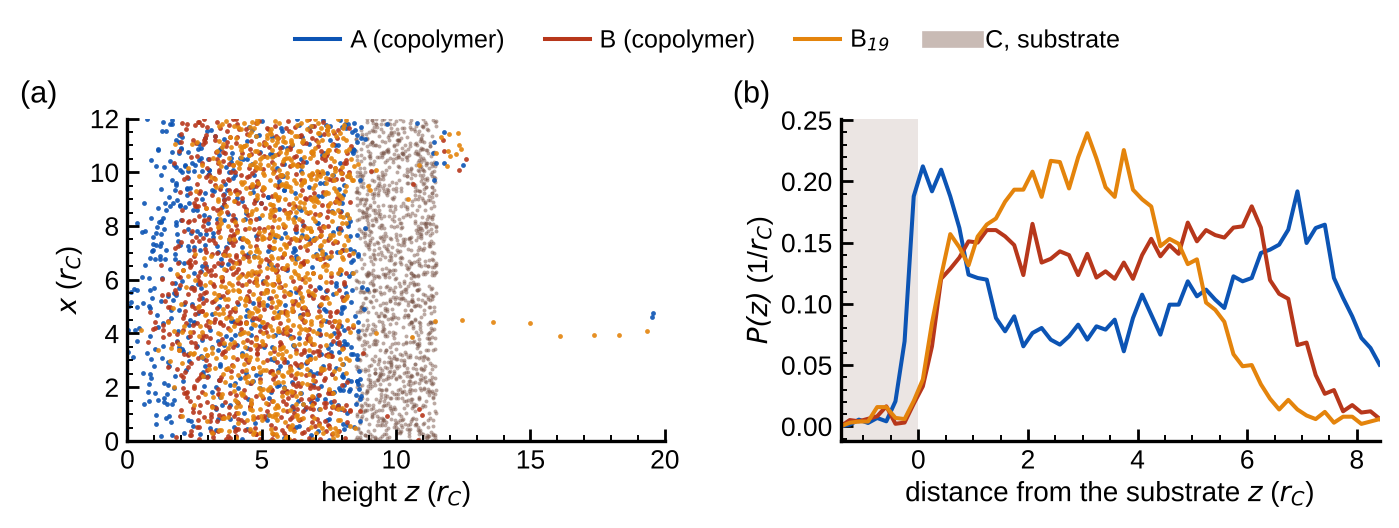

,height of the maximum (r_C)
beads,
A,0.08
B,6.08
B19,3.08


In [13]:
# Solution 2
A3B4 = [A, A, A, B, B, B, B]
pos_m, types_m, molecules_m, bonds_m = build([(A3B4, 0.20), ([B19] * 19, 0.12)], seed=2)
frames_m, profile_m = simulate(pos_m, types_m, molecules_m, bonds_m, 'A3B4_B19')

fig, left, right = two_panels()
side_view(left, frames_m[-1], types_m, kinds=(SUB, A, B, B19))
plot_profile(right, profile_m, kinds=(A, B, B19))
top_legend(fig, [Line2D([], [], color=C['A'], label='A (copolymer)'),
                 Line2D([], [], color=C['B'], label='B (copolymer)'),
                 Line2D([], [], color=C['B19'], label='B$_{19}$'),
                 Line2D([], [], color=C['C'], lw=6, alpha=0.4, label='C, substrate')])
fig.savefig(FIGURES / 'homopolymer_B19.pdf')
plt.show()

pd.DataFrame({'height of the maximum (r_C)': [CENTERS[np.argmax(profile_m[kind])] for kind in (A, B, B19)]},
             index=pd.Index(['A', 'B', 'B19'], name='beads')).round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 3.** A<sub>3</sub>B<sub>4</sub> with B<sub>19</sub> (orange) after 1000 τ; water is hidden.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the final configuration in 3D (Viewer 3).</div>

In [ ]:
show_3d(Atoms([symbols[t] for t in types_m], positions=frames_m[-1], cell=BOX), colors, radius=0.3)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Solution 2 (Figure 3).** The polymers gather on one face into a layered film that spans the box: A beads on the substrate
  (maximum at z = 0.08 r<sub>C</sub>), the B<sub>19</sub> chains in the middle (maximum at z = 3.1 r<sub>C</sub>), the
  copolymer B blocks spread across the core (maximum at z = 6.1 r<sub>C</sub>, next to the outer A layer at z ≈ 7
  r<sub>C</sub>), and A beads facing the water. This is the film of [3]: a hydrophobic polymer layer between two
  amphiphile layers. A few B<sub>19</sub> chains are still on their way to the film.

**Exercise 3 (open). Composition map.** The study of [3] found three regimes of the copolymer and homopolymer amounts:
*incomplete* (too little copolymer, droplets of B<sub>19</sub> on the surface), *complete* (a continuous layered film)
and *cracked* (too much copolymer, which pierces the B<sub>19</sub> layer with hydrophilic channels). Try a few
combinations of the two fractions of exercise 2 and classify each film from the side view and from a top view of the
B<sub>19</sub> beads (a 2D histogram in x and y). With a box this small and runs this short, the result is a sketch;
a map needs the full model of [3].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#005F73; color:#ffffff; padding:8px 14px; border-radius:6px;">Limits of DPD<br><span style="font-size:0.72em; font-weight:normal;">what the model cannot tell, and further steps</span></h2>

- Beads are blobs of fluid, not molecules: apart from the miscibility in a<sub>ij</sub>, all chemical detail is lost.
- The soft potential lets chains pass through each other, so entanglement and the stiffening it brings are missing.
- The 7-bead chains are oligomers; they behave more like surfactants than long block copolymers (notebook 03 shows
  how short chains shift the phase behavior).
- Standard DPD needs a filled box at constant density; drying, or a coating in air, needs another setup.
- The dynamics are too fast (notebook 01), so time scales compare only qualitatively.

The molecular details that DPD cannot give, such as how water molecules move through a hydrophobic layer under strain,
need atomistic MD [6]. Further steps: the same model at full size in LAMMPS [5] on several cores, or in HOOMD-blue [7]
(`hoomd.md.pair.DPD`, fast on a GPU, installed from conda-forge); a rough or curved substrate; and a<sub>ij</sub>
values fitted to atomistic data, the bridge from MD to DPD.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#37474F; color:#ffffff; padding:8px 14px; border-radius:6px;">Summary<br><span style="font-size:0.72em; font-weight:normal;">the answers to the three questions</span></h2>

1. **A<sub>4</sub>B<sub>3</sub> film.** In 1000 τ the chains form two adsorbed aggregates with the A–B–A order of
   [1, 2]: A on the substrate (z = 0.42 r<sub>C</sub>), a B core (z = 2.75 r<sub>C</sub>) and A toward the water; the
   aggregates have not yet spread into a continuous film.
2. **Water.** The water density at the B maximum is 59 % of bulk, an average over the B cores and the uncovered
   substrate between the aggregates.
3. **Block ratio and homopolymer.** A<sub>6</sub>B<sub>1</sub> forms a thin mixed film with no hydrophobic layer
   (37 % water at its B maximum, z = 1.58 r<sub>C</sub>). B<sub>19</sub> forms the middle layer of an
   A<sub>3</sub>B<sub>4</sub> film (z = 3.1 r<sub>C</sub>), between the copolymer layers, as in [3].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">References<br><span style="font-size:0.72em; font-weight:normal;">coating models and programs</span></h2>

1. K. Hasheminejad, *Computational modelling of block copolymer surface coatings at multiple length scales*, doctoral thesis (2026), http://urn.fi/URN:ISBN:978-952-64-2955-7.
2. A. Scacchi, K. Hasheminejad, S. Javan Nikkhah and M. Sammalkorpi, *J. Colloid Interface Sci.* **640**, 809–819 (2023).
3. K. Hasheminejad et al., *Appl. Surf. Sci.* **640**, 158324 (2023).
4. R. D. Groot and P. B. Warren, *J. Chem. Phys.* **107**, 4423–4435 (1997), https://doi.org/10.1063/1.474784.
5. A. P. Thompson et al., *Comput. Phys. Commun.* **271**, 108171 (2022).
6. K. Hasheminejad et al., *Comput. Mater. Sci.* **258**, 114046 (2025).
7. J. A. Anderson, J. Glaser and S. C. Glotzer, *Comput. Mater. Sci.* **173**, 109363 (2020).

</div>